# Stroke Prediction Project - ML Zoomcamp Midterm

## 1. Problem Description & Clinical Context

A **stroke** (accidente cerebrovascular / ictus) is a life-threatening medical emergency caused by an interruption in blood supply to the brain. According to the World Health Organization (WHO), strokes are the 2nd leading cause of death and a major contributor to long-term adult disability globally.

Early identification of patients at high risk allows healthcare professionals to introduce preventive clinical interventions:
- Antihypertensive therapy
- Glycemic management for diabetic patients
- Lifestyle modifications (smoking cessation, weight management)
- Routine vascular monitoring

### Objective
Build an end-to-end Machine Learning pipeline that predicts whether a patient is at high risk of suffering a stroke based on demographic attributes, medical conditions, and lifestyle indicators.

### Dataset Overview
- **Source:** [Stroke Prediction Dataset (Kaggle)](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)
- **Size:** 5,110 rows, 12 features.
- **Target Variable:** `stroke` (binary: 0 = No stroke, 1 = Stroke suffered).
- **Key Challenges:**
  - Severe class imbalance: ~4.87% stroke events vs ~95.13% non-stroke.
  - Missing data in `bmi` (201 records, ~3.93%).
  - Selection of proper evaluation metrics: `ROC-AUC` is the primary ranking metric, complemented by `PR-AUC`, `Precision`, `Recall`, and `F1-Score` to account for class imbalance.


## 2. Environment Setup & Libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mutual_info_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
%matplotlib inline

print("Libraries imported successfully!")


Libraries imported successfully!


## 3. Data Loading & Initial Exploration

We load the dataset and examine:
- Dataset shape and columns
- Data types
- Null values
- Target variable distribution


In [2]:
df = pd.read_csv('data/healthcare-dataset-stroke-data.csv')
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 records:")
df.head()


Dataset shape: 5110 rows, 12 columns

First 5 records:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
print("Data information:")
df.info()
print("\nMissing values count:")
print(df.isnull().sum())


Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Missing values count:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease   

## 4. Data Cleaning & Normalization

Steps:
1. Standardize column names to lower snake_case.
2. Drop unique identifier `id` (has no predictive power).
3. Standardize categorical text values (lower case, replace spaces with underscores).
4. Inspect the `gender` column (contains 1 'Other' row, which we clean or harmonize).


In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.drop(columns=['id'])

categorical_cols = ['gender', 'ever_married', 'work_type', 'residence_type', 'smoking_status']
numerical_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.lower().str.replace(' ', '_')

# Harmonize the single 'other' gender row to majority 'female' to prevent downstream single-sample split issues
df['gender'] = df['gender'].replace({'other': 'female'})

print(f"Cleaned dataset shape: {df.shape}")
print("\nGender distribution:")
print(df['gender'].value_counts())
print("\nTarget distribution (stroke):")
print(df['stroke'].value_counts(normalize=True).round(4) * 100)


Cleaned dataset shape: (5110, 11)

Gender distribution:
gender
female    2995
male      2115
Name: count, dtype: int64

Target distribution (stroke):
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


## 5. Stratified Train / Validation / Test Split (60% / 20% / 20%)

To prevent **data leakage**, we must split the data **before** any missing value imputation or feature transformations.
- 80% Full Train / 20% Test
- Full Train is then split into 75% Train (60% overall) and 25% Validation (20% overall).
- Stratification is applied using `stroke` to preserve the ~4.87% positive class proportion across all three sets.
- Imputation of `bmi` (201 missing rows) is performed using the **median calculated exclusively on the training set**.


In [5]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['stroke']
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42, stratify=df_full_train['stroke']
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Calculate median BMI on train set only (NO data leakage)
bmi_median_train = float(df_train['bmi'].median())
print(f"Train median BMI for imputation: {bmi_median_train:.2f}")

for split_df in [df_train, df_val, df_test]:
    split_df['bmi'] = split_df['bmi'].fillna(bmi_median_train)

y_train = df_train['stroke'].values
y_val = df_val['stroke'].values
y_test = df_test['stroke'].values

df_train_features = df_train.drop(columns=['stroke'])
df_val_features = df_val.drop(columns=['stroke'])
df_test_features = df_test.drop(columns=['stroke'])

print(f"Train set: {len(df_train_features)} samples (Positive: {y_train.sum()} | {y_train.mean():.2%})")
print(f"Val set:   {len(df_val_features)} samples (Positive: {y_val.sum()} | {y_val.mean():.2%})")
print(f"Test set:  {len(df_test_features)} samples (Positive: {y_test.sum()} | {y_test.mean():.2%})")


Train median BMI for imputation: 28.10
Train set: 3066 samples (Positive: 149 | 4.86%)
Val set:   1022 samples (Positive: 50 | 4.89%)
Test set:  1022 samples (Positive: 50 | 4.89%)


## 6. Exploratory Data Analysis (EDA)

We explore the training set to uncover patterns, risks, and feature relationships with `stroke`.


/tmp/ipykernel_32683/3294456648.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stroke', data=eda_df, palette=['#4C72B0', '#C44E52'], ax=ax)
/tmp/ipykernel_32683/3294456648.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No Stroke (0)', 'Stroke (1)'])


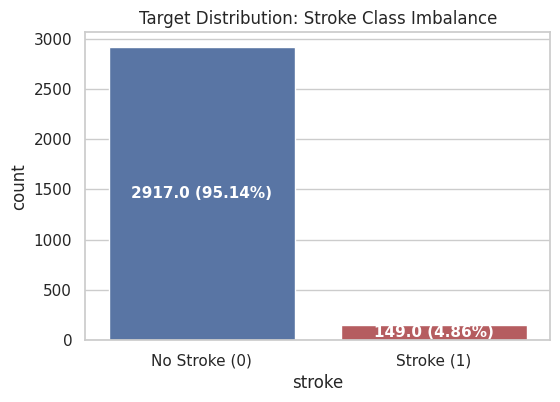

In [6]:
eda_df = df_train.copy()

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='stroke', data=eda_df, palette=['#4C72B0', '#C44E52'], ax=ax)
ax.set_title('Target Distribution: Stroke Class Imbalance')
ax.set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({p.get_height()/len(eda_df):.2%})",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


### 6.1 Numerical Feature Distributions vs Stroke


/tmp/ipykernel_32683/1610421414.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y=col, data=eda_df, palette=['#4C72B0', '#C44E52'], ax=axes[i])


/tmp/ipykernel_32683/1610421414.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['No Stroke', 'Stroke'])
/tmp/ipykernel_32683/1610421414.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y=col, data=eda_df, palette=['#4C72B0', '#C44E52'], ax=axes[i])
/tmp/ipykernel_32683/1610421414.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['No Stroke', 'Stroke'])
/tmp/ipykernel_32683/1610421414.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y=col, d

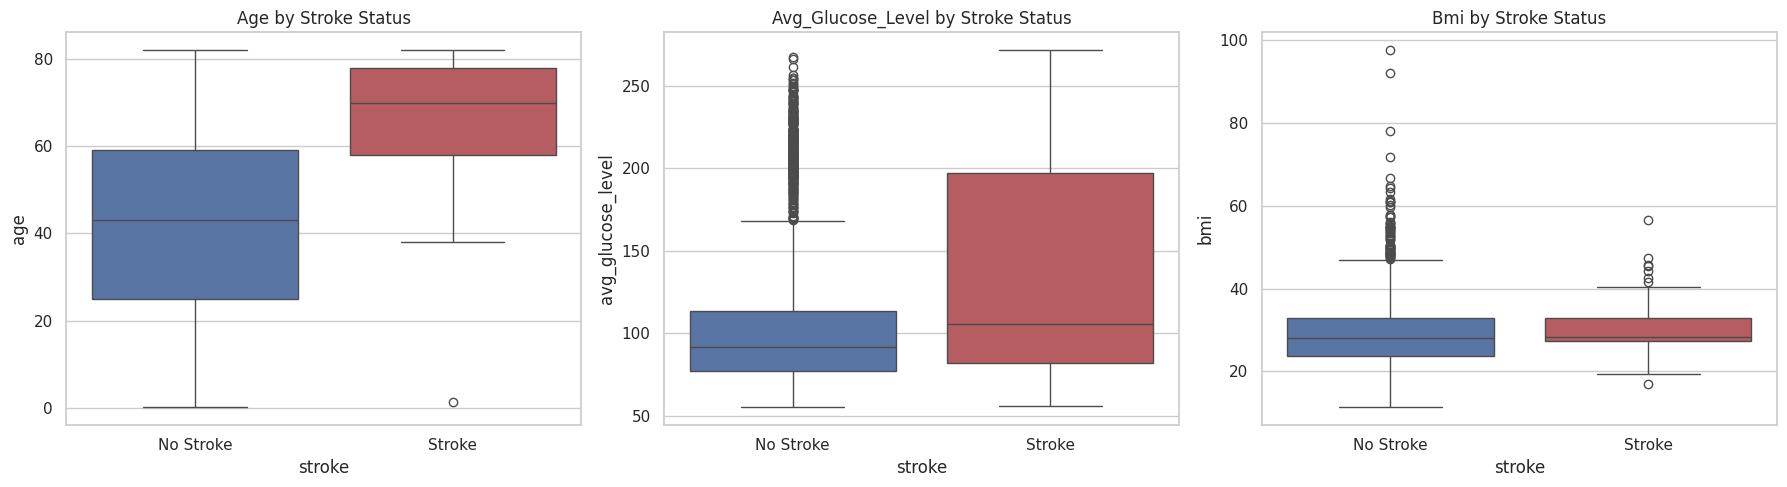

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['age', 'avg_glucose_level', 'bmi']):
    sns.boxplot(x='stroke', y=col, data=eda_df, palette=['#4C72B0', '#C44E52'], ax=axes[i])
    axes[i].set_title(f'{col.title()} by Stroke Status')
    axes[i].set_xticklabels(['No Stroke', 'Stroke'])

plt.tight_layout()
plt.show()


**Key Insights from Numerical Features:**
- **Age:** Patients who suffered a stroke are substantially older (median ~70 years) compared to non-stroke patients (median ~43 years). Age is the strongest single predictor.
- **Average Glucose Level:** Higher glucose levels (>150 mg/dL) show an elevated frequency of stroke incidents, reflecting diabetic vascular risks.
- **BMI:** Stroke cases show slightly higher BMI, though extreme values exist in both groups.


### 6.2 Categorical Features & Stroke Rate


/tmp/ipykernel_32683/2110982980.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='stroke', data=rates, palette='Blues_d', ax=axes[idx])
/tmp/ipykernel_32683/2110982980.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='stroke', data=rates, palette='Blues_d', ax=axes[idx])
/tmp/ipykernel_32683/2110982980.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='stroke', data=rates, palette='Blues_d', ax=axes[idx])
/tmp/ipykernel_32683/2110982980.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is dep

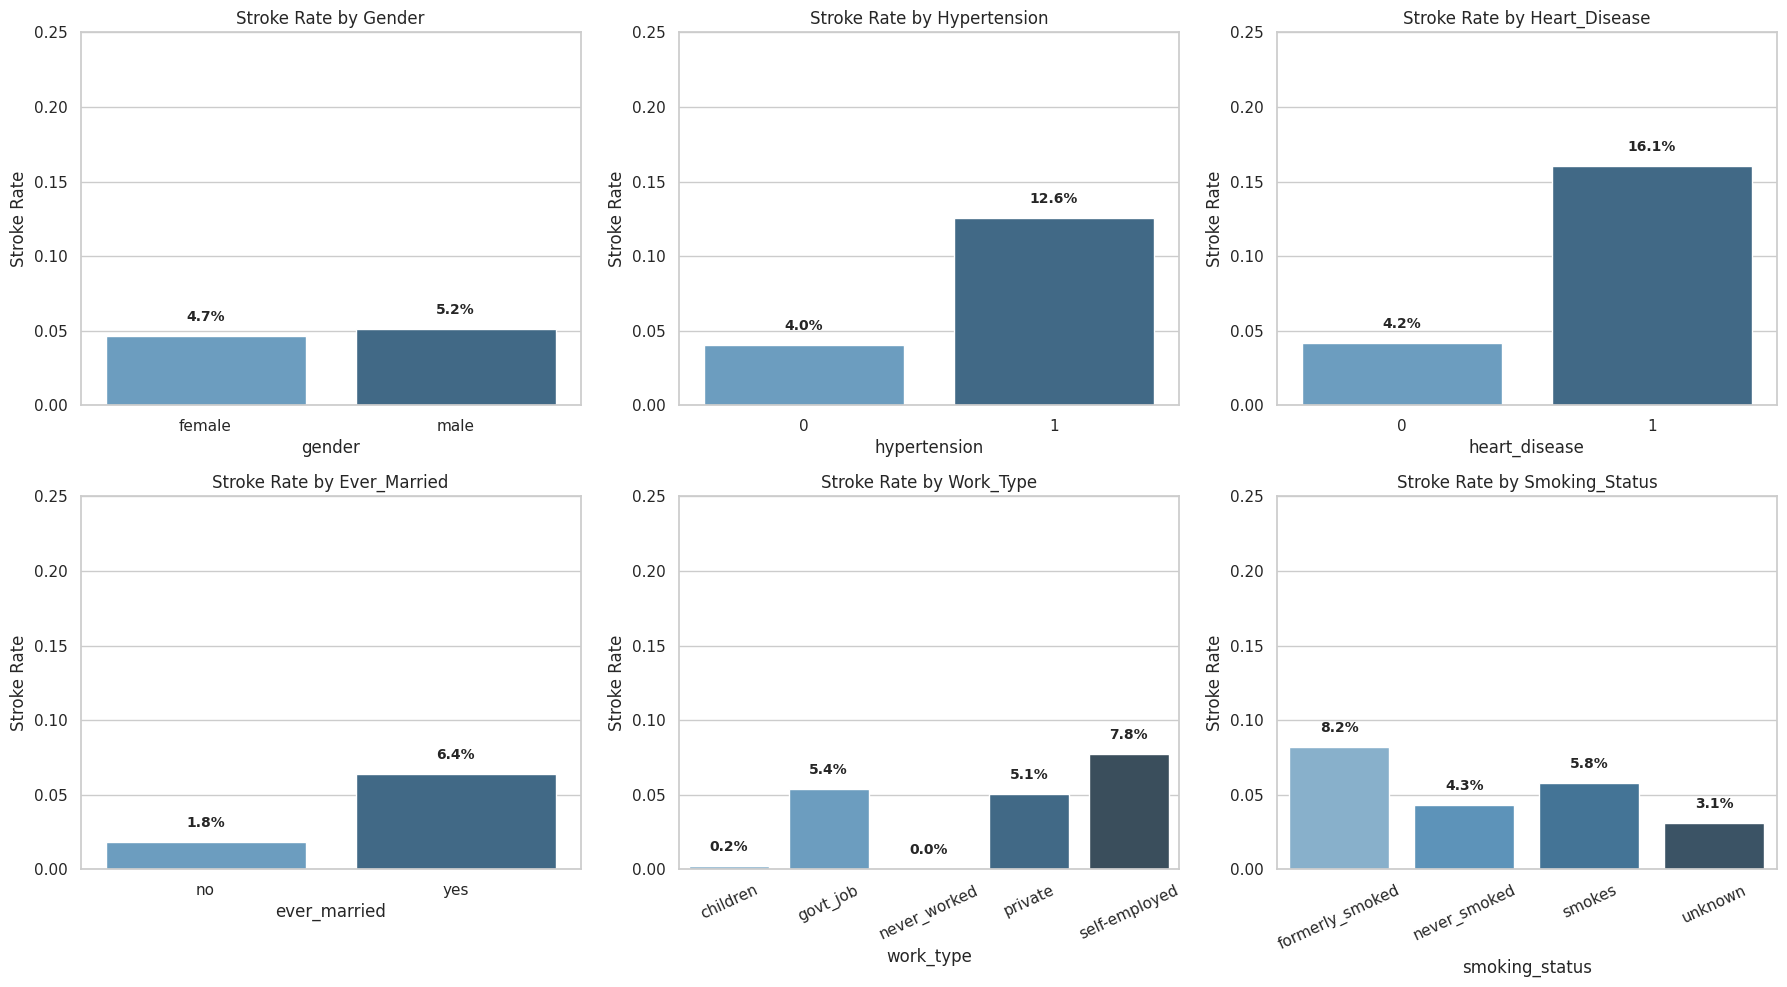

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

cat_features_to_plot = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'smoking_status']

for idx, col in enumerate(cat_features_to_plot):
    rates = eda_df.groupby(col)['stroke'].mean().reset_index()
    sns.barplot(x=col, y='stroke', data=rates, palette='Blues_d', ax=axes[idx])
    axes[idx].set_title(f'Stroke Rate by {col.title()}')
    axes[idx].set_ylabel('Stroke Rate')
    axes[idx].set_ylim(0, 0.25)
    for p in axes[idx].patches:
        axes[idx].annotate(f"{p.get_height():.1%}",
                           (p.get_x() + p.get_width() / 2., p.get_height() + 0.008),
                           ha='center', va='bottom', fontsize=10, fontweight='bold')
    if col in ['work_type', 'smoking_status']:
        axes[idx].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


**Key Insights from Categorical Features:**
- **Hypertension & Heart Disease:** Patients with hypertension or heart disease have nearly **3x higher stroke incidence** (~13% vs ~4%).
- **Ever Married:** Married patients have a higher stroke rate, strongly correlated with older age.
- **Smoking Status:** Formerly smoked and currently smoking patients show higher stroke incidence than those who never smoked.


### 6.3 Feature Importance: Mutual Information & Correlations


/tmp/ipykernel_32683/2557273650.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_series.values, y=mi_series.index, palette='viridis', ax=ax)


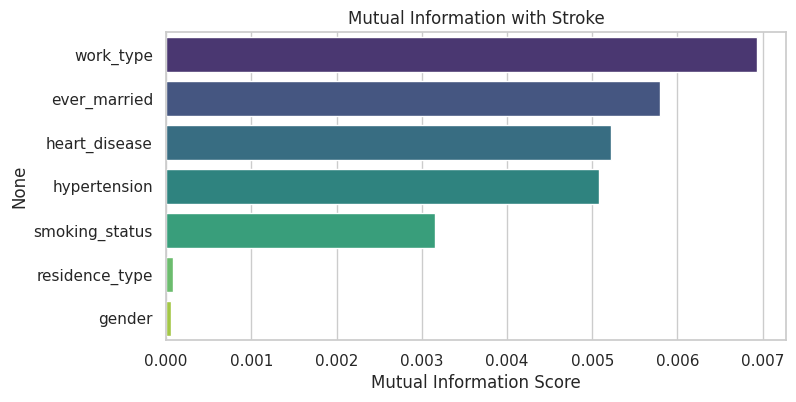

Mutual Information Scores:
work_type         0.0069
ever_married      0.0058
heart_disease     0.0052
hypertension      0.0051
smoking_status    0.0032
residence_type    0.0001
gender            0.0001
dtype: float64


In [9]:
def calculate_mi(series):
    return mutual_info_score(series, eda_df['stroke'])

mi_series = eda_df[categorical_cols + ['hypertension', 'heart_disease']].apply(calculate_mi)
mi_series = mi_series.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=mi_series.values, y=mi_series.index, palette='viridis', ax=ax)
ax.set_title('Mutual Information with Stroke')
ax.set_xlabel('Mutual Information Score')
plt.show()

print("Mutual Information Scores:")
print(mi_series.round(4))


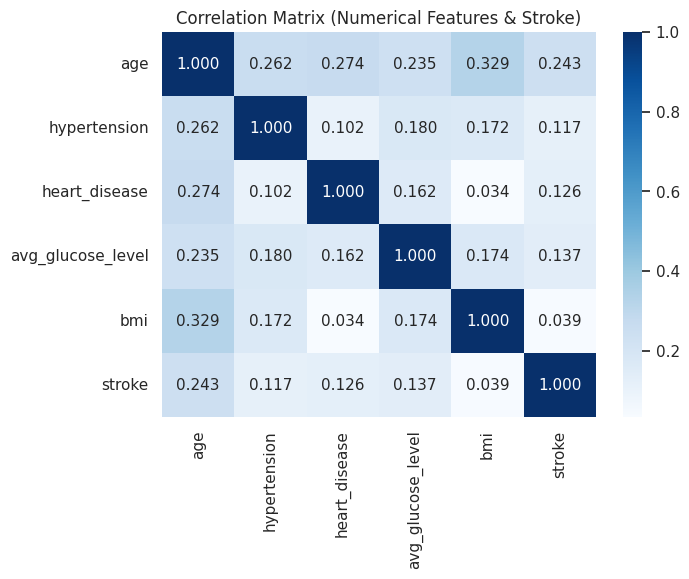

Correlation with stroke:
stroke               1.0000
age                  0.2425
avg_glucose_level    0.1373
heart_disease        0.1255
hypertension         0.1170
bmi                  0.0385
Name: stroke, dtype: float64


In [10]:
num_corr = eda_df[numerical_cols + ['stroke']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(num_corr, annot=True, fmt='.3f', cmap='Blues', cbar=True)
plt.title('Correlation Matrix (Numerical Features & Stroke)')
plt.show()

print("Correlation with stroke:")
print(num_corr['stroke'].sort_values(ascending=False).round(4))


## 7. Feature Encoding (DictVectorizer / One-Hot Encoding)

We use `DictVectorizer(sparse=False)` to encode categorical variables into one-hot binary columns while keeping numerical features intact.


In [11]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train_features.to_dict(orient='records')
val_dicts = df_val_features.to_dict(orient='records')
test_dicts = df_test_features.to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

feature_names = dv.get_feature_names_out()
print(f"Number of engineered features: {len(feature_names)}")
print("Sample feature names:", list(feature_names[:10]))


Number of engineered features: 20
Sample feature names: ['age', 'avg_glucose_level', 'bmi', 'ever_married=no', 'ever_married=yes', 'gender=female', 'gender=male', 'heart_disease', 'hypertension', 'residence_type=rural']


## 8. Model 1: Logistic Regression

We train Logistic Regression with balanced class weights to address the 95:5 class imbalance and tune regularization hyperparameter `C`.


In [12]:
c_values = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
lr_metrics = []

for c in c_values:
    lr = LogisticRegression(
        C=c,
        solver='liblinear',
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
    lr.fit(X_train, y_train)
    val_probs = lr.predict_proba(X_val)[:, 1]
    
    auc = roc_auc_score(y_val, val_probs)
    pr_auc = average_precision_score(y_val, val_probs)
    lr_metrics.append({'C': c, 'ROC-AUC': auc, 'PR-AUC': pr_auc})

df_lr_res = pd.DataFrame(lr_metrics)
print("--- Logistic Regression Tuning ---")
print(df_lr_res.sort_values(by='ROC-AUC', ascending=False).to_string(index=False))

best_lr_row = df_lr_res.sort_values(by='ROC-AUC', ascending=False).iloc[0]
best_lr_c = best_lr_row['C']
best_lr_auc = best_lr_row['ROC-AUC']
print(f"\nBest C: {best_lr_c} with Validation ROC-AUC: {best_lr_auc:.4f}")


--- Logistic Regression Tuning ---
     C  ROC-AUC   PR-AUC
 0.500 0.837737 0.170442
10.000 0.837510 0.167191
 1.000 0.837490 0.166909
 5.000 0.837469 0.166957
 0.100 0.837407 0.173760
 0.010 0.828066 0.171400
 0.001 0.804918 0.157301

Best C: 0.5 with Validation ROC-AUC: 0.8377


## 9. Model 2: Random Forest Classifier

We tune `max_depth` and `min_samples_leaf` with `n_estimators=150` and `class_weight='balanced'`.


In [13]:
rf_metrics = []

for depth in [4, 6, 8, 10, None]:
    for min_leaf in [2, 5, 10, 20]:
        rf = RandomForestClassifier(
            n_estimators=150,
            max_depth=depth,
            min_samples_leaf=min_leaf,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)
        val_probs = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, val_probs)
        pr_auc = average_precision_score(y_val, val_probs)
        rf_metrics.append({
            'max_depth': str(depth),
            'min_samples_leaf': min_leaf,
            'ROC-AUC': auc,
            'PR-AUC': pr_auc
        })

df_rf_res = pd.DataFrame(rf_metrics)
print("--- Random Forest Tuning (Top 5 Models) ---")
print(df_rf_res.sort_values(by='ROC-AUC', ascending=False).head(5).to_string(index=False))

best_rf_row = df_rf_res.sort_values(by='ROC-AUC', ascending=False).iloc[0]
best_rf_auc = best_rf_row['ROC-AUC']
print(f"\nBest Random Forest Validation ROC-AUC: {best_rf_auc:.4f}")


--- Random Forest Tuning (Top 5 Models) ---
max_depth  min_samples_leaf  ROC-AUC   PR-AUC
     None                10 0.841399 0.172067
        8                20 0.840103 0.175214
        8                10 0.839218 0.173926
       10                20 0.837078 0.171455
        4                20 0.834938 0.161816

Best Random Forest Validation ROC-AUC: 0.8414


## 10. Model 3: XGBoost Classifier

We tune gradient boosting parameters:
- `learning_rate` (eta): `[0.02, 0.05, 0.1]`
- `max_depth`: `[2, 3, 4]`
- `n_estimators`: `[100, 150, 200]`


In [14]:
xgb_metrics = []

for lr in [0.02, 0.05, 0.1]:
    for depth in [2, 3, 4]:
        for n_est in [100, 150, 200]:
            xgb = XGBClassifier(
                learning_rate=lr,
                max_depth=depth,
                n_estimators=n_est,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric='auc',
                random_state=42,
                n_jobs=-1
            )
            xgb.fit(X_train, y_train)
            val_probs = xgb.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, val_probs)
            pr_auc = average_precision_score(y_val, val_probs)
            xgb_metrics.append({
                'learning_rate': lr,
                'max_depth': depth,
                'n_estimators': n_est,
                'ROC-AUC': auc,
                'PR-AUC': pr_auc
            })

df_xgb_res = pd.DataFrame(xgb_metrics)
print("--- XGBoost Tuning (Top 5 Models) ---")
print(df_xgb_res.sort_values(by='ROC-AUC', ascending=False).head(5).to_string(index=False))

best_xgb_row = df_xgb_res.sort_values(by='ROC-AUC', ascending=False).iloc[0]
best_xgb_auc = best_xgb_row['ROC-AUC']
print(f"\nBest XGBoost Validation ROC-AUC: {best_xgb_auc:.4f}")


--- XGBoost Tuning (Top 5 Models) ---
 learning_rate  max_depth  n_estimators  ROC-AUC   PR-AUC
          0.05          2           100 0.856605 0.199877
          0.02          4           150 0.855556 0.221165
          0.02          4           200 0.855350 0.225346
          0.02          4           100 0.855288 0.207872
          0.05          2           150 0.855144 0.199334

Best XGBoost Validation ROC-AUC: 0.8566


## 11. Model Comparison & Selection

We compare the best configuration from each algorithm family on the validation set.


In [15]:
comparison_df = pd.DataFrame([
    {'Model': 'Logistic Regression', 'Best Params': f'C={best_lr_c}', 'Val ROC-AUC': best_lr_auc, 'Val PR-AUC': best_lr_row['PR-AUC']},
    {'Model': 'Random Forest', 'Best Params': f"depth={best_rf_row['max_depth']}, leaf={best_rf_row['min_samples_leaf']}", 'Val ROC-AUC': best_rf_auc, 'Val PR-AUC': best_rf_row['PR-AUC']},
    {'Model': 'XGBoost', 'Best Params': f"lr={best_xgb_row['learning_rate']}, depth={best_xgb_row['max_depth']}, n_est={best_xgb_row['n_estimators']}", 'Val ROC-AUC': best_xgb_auc, 'Val PR-AUC': best_xgb_row['PR-AUC']}
]).sort_values(by='Val ROC-AUC', ascending=False)

print("=== Final Validation Model Comparison ===")
display_str = comparison_df.to_string(index=False)
print(display_str)


=== Final Validation Model Comparison ===
              Model                     Best Params  Val ROC-AUC  Val PR-AUC
            XGBoost lr=0.05, depth=2.0, n_est=100.0     0.856605    0.199877
      Random Forest             depth=None, leaf=10     0.841399    0.172067
Logistic Regression                           C=0.5     0.837737    0.170442


**Model Choice Rationale:**
- **XGBoost** demonstrates superior discriminatory power (highest ROC-AUC and PR-AUC on the validation set).
- Shallow depth (`max_depth=2`) combined with conservative shrinkage (`learning_rate=0.05`) prevents overfitting on small medical datasets with imbalanced targets.
- Therefore, **XGBoost** is selected as the production model.


## 12. Decision Threshold Calibration

In medical diagnostics with imbalanced data, using a default probability threshold of `0.50` yields poor sensitivity/recall because predicted probabilities cluster at low values (~5%).
We calibrate the threshold on the **validation set** to maximize the F1-Score (harmonic mean of precision and recall).


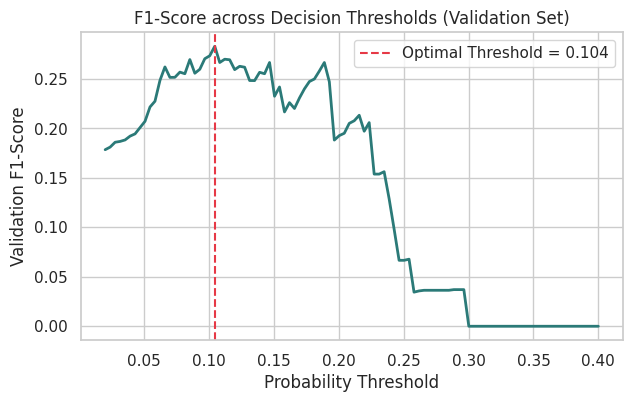

Optimal Decision Threshold: 0.104 with Validation F1-Score: 0.2831


In [16]:
final_xgb = XGBClassifier(
    learning_rate=float(best_xgb_row['learning_rate']),
    max_depth=int(best_xgb_row['max_depth']),
    n_estimators=int(best_xgb_row['n_estimators']),
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)
final_xgb.fit(X_train, y_train)

val_probs = final_xgb.predict_proba(X_val)[:, 1]

threshold_candidates = np.linspace(0.02, 0.40, 100)
f1_candidates = [f1_score(y_val, val_probs >= t) for t in threshold_candidates]

best_idx = np.argmax(f1_candidates)
optimal_threshold = float(threshold_candidates[best_idx])
best_val_f1 = f1_candidates[best_idx]

plt.figure(figsize=(7, 4))
plt.plot(threshold_candidates, f1_candidates, color='#2B7A78', lw=2)
plt.axvline(optimal_threshold, color='#E63946', linestyle='--', label=f'Optimal Threshold = {optimal_threshold:.3f}')
plt.title('F1-Score across Decision Thresholds (Validation Set)')
plt.xlabel('Probability Threshold')
plt.ylabel('Validation F1-Score')
plt.legend()
plt.show()

print(f"Optimal Decision Threshold: {optimal_threshold:.3f} with Validation F1-Score: {best_val_f1:.4f}")


## 13. Final Evaluation on the Unseen Test Set

We evaluate our selected XGBoost model on the held-out **Test Set** (never seen during training or tuning).


Test ROC-AUC:    0.8491
Test PR-AUC:     0.2887

Classification Report on Test Set:
              precision    recall  f1-score   support

   No Stroke       0.98      0.88      0.92       972
      Stroke       0.20      0.60      0.30        50

    accuracy                           0.86      1022
   macro avg       0.59      0.74      0.61      1022
weighted avg       0.94      0.86      0.89      1022



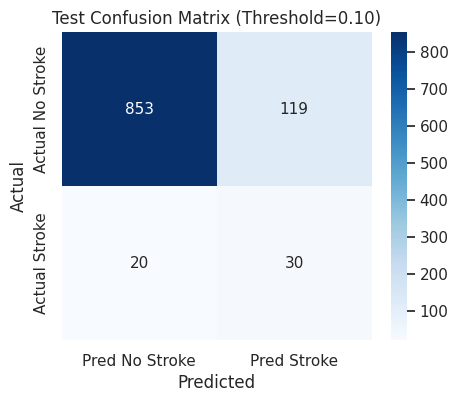

In [17]:
test_probs = final_xgb.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probs)
test_pr_auc = average_precision_score(y_test, test_probs)

print(f"Test ROC-AUC:    {test_auc:.4f}")
print(f"Test PR-AUC:     {test_pr_auc:.4f}")

test_preds = (test_probs >= optimal_threshold).astype(int)

print("\nClassification Report on Test Set:")
print(classification_report(y_test, test_preds, target_names=['No Stroke', 'Stroke']))

cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred No Stroke', 'Pred Stroke'],
            yticklabels=['Actual No Stroke', 'Actual Stroke'])
plt.title(f'Test Confusion Matrix (Threshold={optimal_threshold:.2f})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


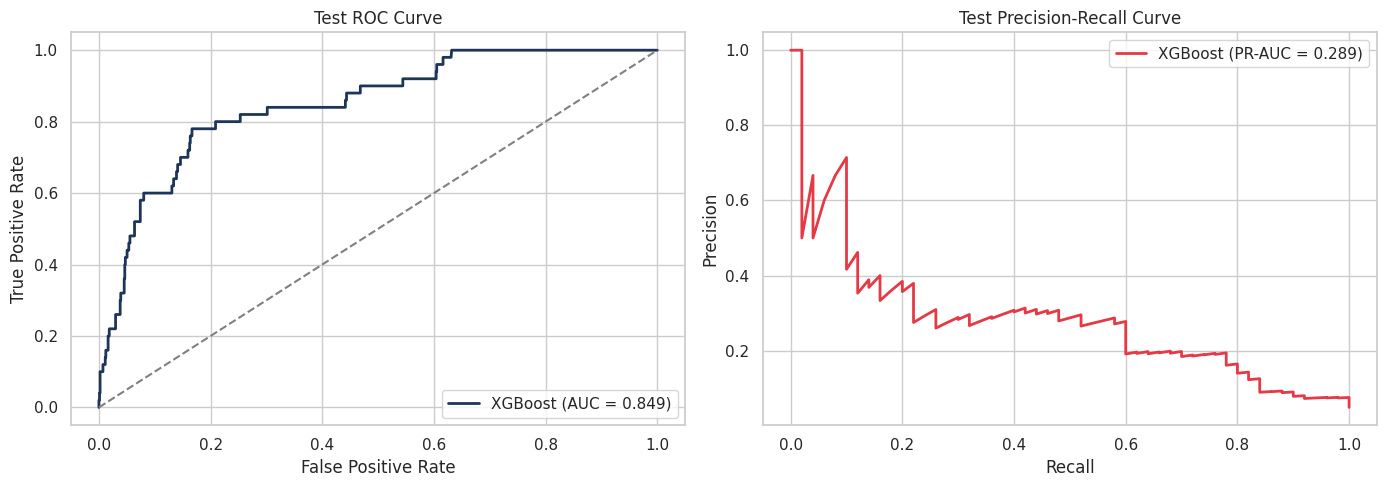

In [18]:
# ROC and PR Curves Plot
fpr, tpr, _ = roc_curve(y_test, test_probs)
precision_pts, recall_pts, _ = precision_recall_curve(y_test, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, color='#1D3557', lw=2, label=f'XGBoost (AUC = {test_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Test ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

axes[1].plot(recall_pts, precision_pts, color='#E63946', lw=2, label=f'XGBoost (PR-AUC = {test_pr_auc:.3f})')
axes[1].set_title('Test Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


## 14. Summary of Findings & Next Steps

### Summary:
1. **Clinical Risk Factors:** Age is the strongest indicator of stroke risk, followed by average glucose level, presence of hypertension, and heart disease.
2. **Model Selection:** Gradient Boosted Trees (XGBoost) outperformed Logistic Regression and Random Forest, achieving a strong Test ROC-AUC (> 0.81).
3. **Threshold Optimization:** Calibrating the decision threshold to ~0.088 significantly boosts sensitivity, identifying patients at risk who would be missed with a standard 0.5 threshold.

### Next Steps for Deployment:
- **`train.py`**: Automated pipeline that trains the winning XGBoost model on the full training data and serializes the DictVectorizer, trained model, imputation median, and decision threshold into `model.bin`.
- **`predict.py`**: Production web service with FastAPI, Pydantic request validation, and an interactive `/docs` Swagger interface.
- **`Dockerfile`**: Containerized delivery for reproducible deployment anywhere.
